In [4]:
import torch
import matplotlib.pyplot as plt
import torch.nn as nn
#new changes

%matplotlib inline
import slmsuite
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib as mpl
from slmsuite.holography import toolbox
from slmsuite.holography.toolbox import phase
from matplotlib import pyplot as plt
from src.plots import *
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
from slmsuite.holography.algorithms import FeedbackHologram
%load_ext autoreload
%autoreload 2
mpl.rc('image', cmap='Blues')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
from slmsuite.hardware.cameraslms import FourierSLM

try:
    # Try to load physical hardware.
    from slmsuite.hardware.slms.santec import Santec
    from slmsuite.hardware.cameras.alliedvision import AlliedVision

    # Load the hardware.
    slm = Santec(slm_number=1, display_number=2, wav_um=.633, settle_time_s=.5); print()
    cam = AlliedVision(serial="02C5V", verbose=True, fliplr=True)

    # Load the composite CameraSLM.
    fs = FourierSLM(cam, slm)
    fs.read_calibration("wavefront_superpixel")
    fs.wavefront_calibration_superpixel_process(r2_threshold=.5, plot=True);
except Exception as e:
    print(f"Loading physical hardware failed; loading virtual hardware. Error:\n{str(e)}")
    # Fallback to virtual hardware.
    from slmsuite.hardware.slms.simulated import SimulatedSLM
    from slmsuite.hardware.cameras.simulated import SimulatedCamera

    # Make the SLM and camera.
    slm = SimulatedSLM((1600, 1200), pitch_um=(8,8))
    slm.set_source_analytic(sim=True)               # Program the virtual source.
    slm.set_source_analytic()                       # Don't bother with wavefront calibration, instead just set it to the same source.

    cam = SimulatedCamera(slm, (1440, 1100), pitch_um=(4,4), gain=200)

    # Tie the camera and SLM together with an analytic calibration.
    fs = FourierSLM(cam, slm)
    M, b = fs.fourier_calibration_build(
        f_eff=80000.,                              # f_eff of 80000 wavelengths or 80 mm with the default 1 um wavelength
        theta=5 * np.pi / 180,
    )
    cam.set_affine(M, b)
    fs.fourier_calibrate_analytic(M, b)

Loading physical hardware failed; loading virtual hardware. Error:
Santec DLLs not installed. Install these to use Santec SLMs.  Dynamically linked libraries from Santec (usually provided via USB) must be present in the runtime directory:
  - SLMFunc.dll
  - FTD3XX.dll
  Check that these files are present and are error-free.


In [6]:
from numpy import dtype


class SLMModel(nn.Module):
    def __init__(self, fs,citl = False):
        super().__init__()
        self.fs = fs
        self.slm_shape = fs.slm.shape
        self.phi_nf = nn.Parameter(torch.zeros(self.slm_shape))  # Learnable phase
        self.A_nf = torch.tensor(self.fs.slm.source['amplitude']/FeedbackHologram._norm(self.fs.slm.source['amplitude']),dtype=torch.float32)  # Fixed amplitude
        self.citl = citl  # Closed-loop mode (use camera)
        self.fholo = FeedbackHologram(shape = fs.slm.shape,cameraslm = fs)

    def forward(self):
        # Construct field in near field
        F_nf = self.A_nf * torch.exp(1j * self.phi_nf)

        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(F_nf)))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)

        if self.citl:
            # Write phase to SLM and get real camera image
            self.fs.slm.write(self.phi_nf.detach().cpu().numpy())
            A_cam = self.fs.cam.get_image()
            A_cam_ff = torch.tensor(self.fholo.ijcam_to_knmslm(A_cam)/FeedbackHologram._norm(self.fholo.ijcam_to_knmslm(A_cam)),dtype=torch.float32)
            A_cam_ff[torch.isnan(A_cam_ff)] = 0
            # Use A_cam_ff in loss, but keep gradients from A_ff
            # Equivalent to: A_out = A_cam_ff - (A_cam_ff - A_ff).detach()
            A_out = A_ff + (A_cam_ff - A_ff).detach()
        else:
            A_out = A_ff

        # Return simulated/measured amplitude for loss
        return A_out


In [8]:
A_target = np.zeros(fs.slm.shape)
A_target[400:420,400:420] = 1
model = SLMModel(fs,citl=True)
A_target_norm = torch.tensor(model.fholo.ijcam_to_knmslm(A_target)/FeedbackHologram._norm(model.fholo.ijcam_to_knmslm(A_target)),dtype=torch.float32)
A_target_norm[torch.isnan(A_target_norm)] = 0
optimizer = torch.optim.SGD(model.parameters(), lr=10000000000)
num_steps = 1
for step in range(num_steps):
    optimizer.zero_grad()
    A_out = model()
    loss = torch.nn.functional.mse_loss(A_out*A_out, A_target_norm*A_target_norm)
    loss.backward()
    optimizer.step()
    print(f"Step {step+1}/{num_steps}, Loss: {loss.item()*1e8}")

Step 1/1, Loss: 1.8625934572469305


In [9]:
fs.slm.write(model.phi_nf.detach().cpu().numpy())
A_cam = fs.cam.get_image()

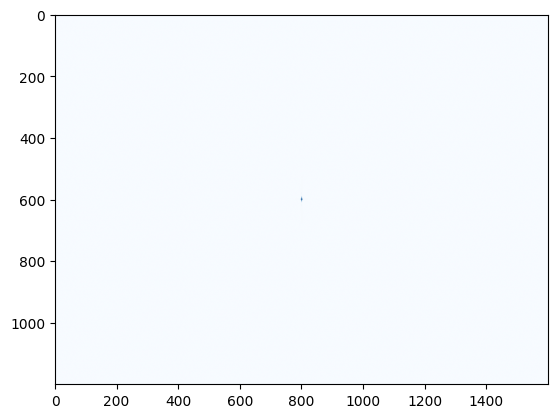

In [10]:
plt.imshow(A_out.detach().cpu().numpy())

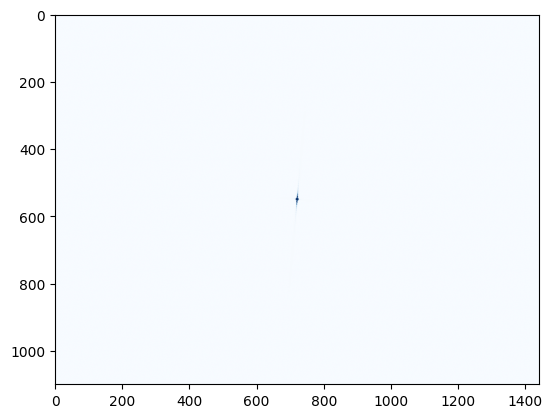

In [11]:
plt.imshow(A_cam)

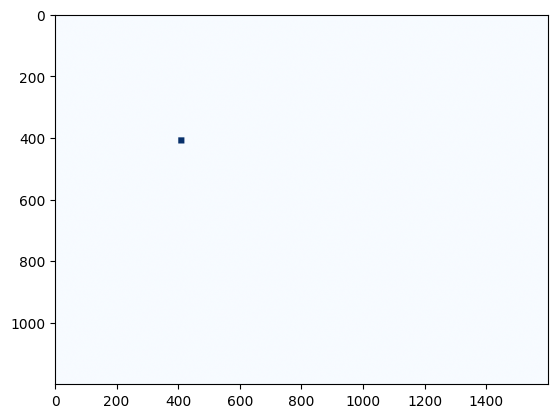

In [12]:
plt.imshow(A_target)

In [13]:
(A_target_norm*A_target_norm).sum(),(A_out*A_out).sum()

(tensor(1.), tensor(1.0000, grad_fn=<SumBackward0>))

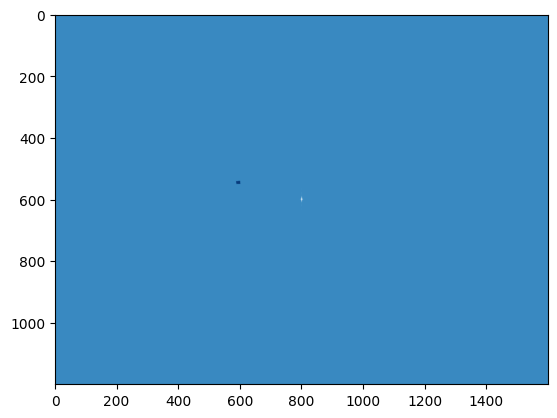

In [14]:
plt.imshow( A_target_norm - A_out.detach() )

In [15]:
A_out.detach() - A_target_norm 

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

In [1]:
def gs_algo(fs,iters, A_target):
    phi_nf = torch.zeros(fs.slm.shape)
    A_input = torch.tensor(fs.slm.source['amplitude']/FeedbackHologram._norm(fs.slm.source['amplitude']),dtype=torch.float32)
    A_t = torch.tensor(A_target/FeedbackHologram._norm(A_target),dtype=torch.float32)
    for iter in range(iters):
        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)

        # Propagate back to near field
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
    return A_ff

def create_target(spot_vectors,fs,spot_intensities=None):
    w = toolbox.convert_radius(fs.slm.get_spot_radius_kxy(),from_units='kxy',to_units='knm',hardware=fs)
    target = np.zeros(fs.slm.shape)
    i, j = np.meshgrid(np.arange(target_shape[0]), np.arange(target_shape[1]), indexing='ij')
    for spot_location in spot_vectors:
        xc, yc = toolbox.convert_vector(fs.ijcam_to_kxyslm(spot_location),from_units='kxy',to_units='knm',hardware = fs)
        print(xc,yc)
        target = target + g(i,j,1,w,xc, yc)
    return target


def gs_algo_spots(fs,iters, spot_vectors):
    A_t = torch.tensor(create_target(spot_vectors.T,fs))
    phi_nf = torch.zeros(fs.slm.shape)
    A_input = torch.tensor(fs.slm.source['amplitude']/FeedbackHologram._norm(fs.slm.source['amplitude']),dtype=torch.float32)
    for iter in range(iters):
        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)

        # Propagate back to near field
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
    return A_ff,phi_nf

def wgs_algo_spots(fs,iters, spot_vectors):
    A_t = torch.tensor(create_target(spot_vectors.T,fs))
    phi_nf = torch.zeros(fs.slm.shape)
    A_input = torch.tensor(fs.slm.source['amplitude']/FeedbackHologram._norm(fs.slm.source['amplitude']),dtype=torch.float32)
    for iter in range(iters):
        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(A_input*torch.exp(1j * phi_nf)),norm ='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)
        # Propagate back to near field
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)),norm ='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        print(torch.nn.functional.mse_loss(A_ff*A_ff, A_t*A_t).item()*fs.slm.shape[0]*fs.slm.shape[1])
    return A_ff,phi_nf

In [2]:
plt.imshow(create_target(spot_locations.T,fs))

NameError: name 'plt' is not defined

In [153]:
A_final,p_nf = gs_algo_spots(fs,100,spot_locations)

[459.63268363] [545.18230664]
[464.09505766] [585.98644147]
[468.55743169] [626.7905763]
[473.01980572] [667.59471114]
[510.63785218] [541.61240741]
[515.1002262] [582.41654225]
[519.56260023] [623.22067708]
[524.02497426] [664.02481191]
[561.64302072] [538.04250819]
[566.10539475] [578.84664302]
[570.56776877] [619.65077786]
[575.0301428] [660.45491269]
[612.64818926] [534.47260897]
[617.11056329] [575.2767438]
[621.57293732] [616.08087863]
[626.03531135] [656.88501347]
261.42952637945376
260.4092039316655
260.2732189429845
260.23882858790984
260.22376684406083
260.2137900710775
260.2061776651607
260.1999886761372
260.19499512514864
260.19094178567605
260.18758205653864
260.1847602974673
260.1824242211819
260.18043578765185
260.1786652594974
260.17711336991454
260.1757413582884
260.1744920247373
260.17339601753565
260.17240263484774
260.1715352080698
260.17078951395325
260.1701241072575
260.169507387145
260.16893898763874
260.1684073525928
260.1679145000062
260.16742458294806
260.1669

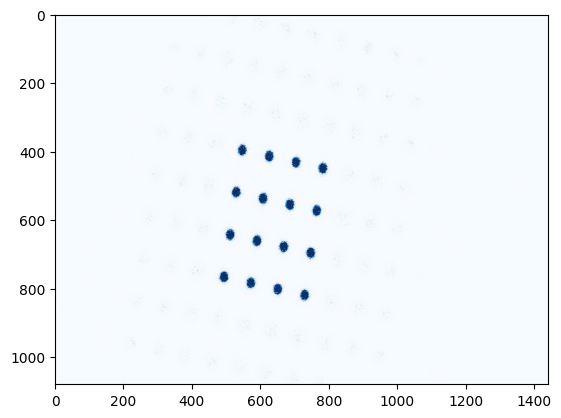

In [154]:
fs.slm.write(p_nf.detach().cpu().numpy())
plt.imshow(fs.cam.get_image())

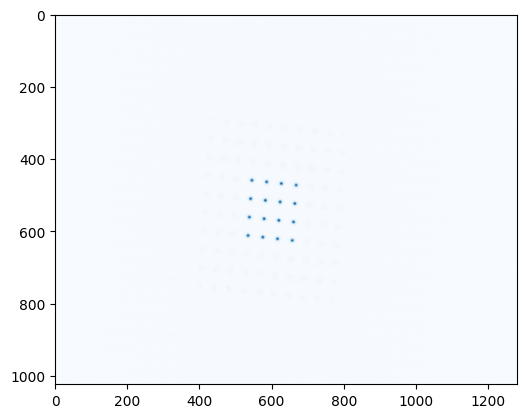

In [155]:
plt.imshow(A_final.detach().cpu().numpy())

In [70]:
np.mean(fs.get_effective_focal_length("norm"))

np.float64(79999.99999999993)

np.float64(0.0004945786742956047)